# `ammico` workshop November 2026: comparing models with OpenRouter

*Delia Dumitrescu, Inga Ulusoy, Dmitrii Kapitan*

With `ammico`, you can analyze text on images and image content at the same time, see https://ssciwr.github.io/AMMICO/. In this notebook, we run the same analysis with several vision-language models hosted on [OpenRouter](https://openrouter.ai) and compare the results. First we start by importing the packages.

In [1]:
import openrouter_utils as OR

import ammico

This imports all the functionality from `ammico`. To analyze images, you can manually upload images to the Jupyter server; in this workshop, we will use pre-prepared datasets in `/home/jovyan/data_mounts/webdav`. The helper functions for running several models are in `openrouter_utils.py`, next to this notebook.

# Step 1: Read your data into AMMICO

`ammico` reads in files from a directory. You can iterate through directories in a recursive manner and filter by extensions. Note that the order of the files may vary on different OS. Reading in these files creates a dictionary `image_dict`, with one entry per image file, containing the file path and filename. This dictionary is the main data structure that ammico operates on and is extended successively with each detector run as explained below.

For reading in the files, the ammico function `find_files` is used, with optional keywords:

| input key | input type | possible input values |
| --------- | ---------- | --------------------- |
`path` | `str` | the directory containing the image files (defaults to the location set by environment variable `AMMICO_DATA_HOME`) |
| `pattern` | `str\|list` | the file extensions to consider (defaults to "png", "jpg", "jpeg", "gif", "webp", "avif", "tiff") |
| `recursive` | `bool` | include subdirectories recursively (defaults to `True`) |
| `limit` | `int` | maximum number of files to read (defaults to `20`, for all images set to `None` or `-1`) |
| `random_seed` | `int` | the random seed for shuffling the images; applies when only a few images are read and the selection should be preserved (defaults to `None`) |

Since every model is billed per request on OpenRouter, you may want to start with a small number of images by setting `limit`. All models are run on exactly the same images.

In [2]:
# Define your data path
data_path = (
    "/home/jovyan/data_mounts/webdav/dataset_politicians/"  # the selected directory
)

# Find files and create the image dictionary
image_dict = ammico.find_files(
    path=data_path,
    limit=-1,  # Limit the number of files to process (optional)
)

# 2. Connect to the models

We will ask the same questions about the images to several vision-language models and compare their answers.

[OpenRouter](https://openrouter.ai) gives access to many hosted models (OpenAI, Google, Anthropic, Qwen, Meta, Mistral, ...) through a single **OpenAI-compatible API** and a single API key. You need an account and an API key, which you can create at [openrouter.ai/keys](https://openrouter.ai/keys). The key is read from the environment variable `OPENROUTER_API_KEY`; if it is not set, you are asked to enter it below. Do not write your API key directly into the notebook, in particular if you share the notebook with others!

**Privacy note:** with OpenRouter your images are sent to a third party (OpenRouter and the provider of the selected model). Do not use this setup for data that must not leave your institution.

Any model on OpenRouter that accepts images as input can be used, see the [OpenRouter model list](https://openrouter.ai/models?input_modalities=image), where you also see the price per token. The model id is the name shown on the model page, prefixed with the provider, for example `openai/gpt-4o-mini`. Add or remove model ids in the list below.

In [4]:
# Connect to OpenRouter (asks for the API key if OPENROUTER_API_KEY is not set)
OR.connect()

models = [
    "google/gemini-2.5-flash",
    "qwen/qwen2.5-vl-72b-instruct",
    "meta-llama/llama-4-maverick",
]

Enter your OpenRouter API key:  ········


Connected to OpenRouter (key starts with 'sk-or-v1').


Then, we create an instance of the Python class that handles the visual question answering task. It holds one `ammico.ImageSummaryDetector` per model, each working on its own copy of `image_dict`, so that the results of the different models do not overwrite each other.

Many models on OpenRouter are served from a pool shared between all users. When it is busy, the request is rejected with a **rate limit error** (`Error code: 429`); such requests are retried with increasing waiting times. To avoid the rate limit, the number of requests sent at the same time is limited by `max_parallel_images` and `max_parallel_requests` (one request per question); lower these numbers if you still see many rate limit errors. Reasoning models "think" before they answer, which can leave the answer empty, so reasoning is switched off (`disable_reasoning=True`).

In [5]:
image_summary_vqa = OR.MultiModelDetector(
    models,
    image_dict,
    max_parallel_images=4,  # images processed at the same time
    max_parallel_requests=2,  # requests (questions) per image at the same time
    disable_reasoning=True,
)

# 3. Run the content analysis: Visual question answering

Now we ask questions about the images. For this, provide a list of questions and pass it to the Python class that you have instantiated above. All models answer the same questions:

In [6]:
list_of_questions = [
    "Is there a politician in the picture?",
    "Is there a politician in the picture? Answer yes, no or dk. Don't guess.",
    "Is there a politician in the picture? Answer yes, no, or dk. Briefly justify your answer and, if there is a politician, give the name. Don't guess.",
    "Is any of the following politicians in the picture: Donald Trump, Volodymyr Zelenskyy or Vladimir Putin? Answer yes or no. If yes, give the name. Don't guess.",
]  # add or replace with your own questions

In [7]:
answers = image_summary_vqa.analyse_images_from_dict(
    analysis_type="questions",
    list_of_questions=list_of_questions,
    is_concise_summary=True,
    is_concise_answer=True,
)

google/gemini-2.5-flash: running on 265 images ...
google/gemini-2.5-flash: RateLimitError, retry 1/6 in 6 s
google/gemini-2.5-flash: RateLimitError, retry 1/6 in 6 s
google/gemini-2.5-flash: RateLimitError, retry 1/6 in 6 s
google/gemini-2.5-flash: RateLimitError, retry 1/6 in 6 s
google/gemini-2.5-flash: RateLimitError, retry 1/6 in 6 s
google/gemini-2.5-flash: RateLimitError, retry 1/6 in 7 s
google/gemini-2.5-flash: done in 149.8 s
qwen/qwen2.5-vl-72b-instruct: running on 265 images ...
qwen/qwen2.5-vl-72b-instruct: done in 161.7 s
meta-llama/llama-4-maverick: running on 265 images ...
meta-llama/llama-4-maverick: done in 188.8 s


Again for your convenience we display the images and the answers of all models to the questions together below:

In [ ]:
OR.show_answers(answers, list_of_questions)

# 4. Export the results

To export the results for further processing, convert the image dictionaries of all models into one pandas dataframe. Each row corresponds to one image analyzed by one model; the column `model` tells you which model produced the result.

In [8]:
image_df = OR.get_dataframe(answers)

Inspect the dataframe:

In [9]:
image_df.head(5)

,model,filename,vqa
0,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_politi...,"[Yes, there is a politician in the picture., Y..."
1,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_politi...,"[Yes, there is a politician in the picture., Y..."
2,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_politi...,"[Yes, there are two politicians in the picture..."
3,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_politi...,"[Yes, there is a politician in the picture. Do..."
4,google/gemini-2.5-flash,/home/jovyan/data_mounts/webdav/dataset_politi...,"[Yes, there is a politician in the picture., Y..."


Export the dataframe to a csv file, and additionally the results of each model to its own csv file (`<provider>__<model>.csv`):

In [10]:
image_df.to_csv("./politicians_data_out.csv")
OR.save_per_model(image_df, "./politicians_results")

google/gemini-2.5-flash: saved to politicians_results/google__gemini-2.5-flash.csv
qwen/qwen2.5-vl-72b-instruct: saved to politicians_results/qwen__qwen2.5-vl-72b-instruct.csv
meta-llama/llama-4-maverick: saved to politicians_results/meta-llama__llama-4-maverick.csv


# 5. Analyse the results
You can compare the results to the manual labels and observe how accurate the different VLMs capture the content.

# Question accuracy for several models

Which of several questions (prompts) gets the most images right for each model, and do the models agree on which question works best?

**How to use:** run the VQA with ammico on one of the course datasets and save the result as a csv file. Fill in the two paths in the next cell and run all cells. Tables and plots are saved in `comparison_results/` next to the (first) result file.

In [13]:
# ============ SETTINGS: the only cell you need to change ============
RESULTS_FILES = [  # csv file(s) with the model answers, one file per model
    "/home/jovyan/politicians_results/google__gemini-2.5-flash.csv",  # (or one file with several models); glob patterns work,
    "/home/jovyan/politicians_results/meta-llama__llama-4-maverick.csv",  # e.g. "../my_results/emotions_*.csv"
    "/home/jovyan/politicians_results/qwen__qwen2.5-vl-72b-instruct.csv",  # e.g. "../my_results/emotions_*.csv"
]
IMAGE_DIR = data_path  # folder with the images, here the same as above

**Datasets** – the dataset (emotions, politicians or symbols) is detected from the image names in the result file, so only the paths change. The paths are relative to this notebook.

The images can be in one flat folder; they are only needed for the image examples. Questions, ground truth and expected answers are defined in `DATASETS` in `vqa_eval_utils.py`; the ground-truth and question files are read from `ground_truth/` next to the image folder (or from the `*_output/` folders of the course repository). The answers must be to the questions in these files, in the same order.

## 5.1 Data and questions

In [14]:
import vqa_eval_utils as U

run = U.load(RESULTS_FILES, IMAGE_DIR, "question_accuracy_models")
U.show_questions(run)

dataset: politicians  |  models: gemini-2.5-flash, llama-4-maverick, qwen2.5-vl-72b-instruct
images: 265 in the results, 265 with ground truth, 265 found in /home/jovyan/data_mounts/webdav/dataset_politicians/
images answered completely by all models (used for the comparison): 265
output folder: /home/jovyan/politicians_results/comparison_results/question_accuracy_models


,type,style,question,expected answer (label -> answer)
qid,,,,
Q1,politician,open,Is there a politician in the picture?,"politician: yes -> yes, no -> no"
Q2,politician,constrained,"Is there a politician in the picture? Answer yes, no or dk. Don't guess.","politician: yes -> yes, no -> no"
Q3,politician,constrained+justify,"Is there a politician in the picture? Answer yes, no, or dk. Briefly justify your answer and, if there is a politician, give the name. Don't guess.","politician: yes -> yes, no -> no"
Q4,named,constrained,"Is any of the following politicians in the picture: Donald Trump, Volodymyr Zelenskyy or Vladimir Putin? Answer yes or no. If yes, give the name. Don't guess.","named_politician: none -> no, trump -> yes, zelenskyy -> yes, putin -> yes"


## 5.2 From free text to answers
Each answer is mapped to a category (yes / no / dk, …) by the rules of its question type. `exact`, `first` and `package_code` are safe; the keyword rules (`kw_*`) are heuristics, so read the sample of raw answers below against their `normalised` value. Only images answered by all models are used, so all models are compared on the same images.

In [15]:
U.show_normalisation(run)

answer_is  exact  first  kw_affirm  kw_dk  kw_negated  kw_none_of_listed  kw_opposite  unparsed
qid model                                                                                                                   
Q1  gemini-2.5-flash                 0     61    142          6     54           2                  0            0         0
    llama-4-maverick                 1     51    160         14     32           7                  0            0         0
    qwen2.5-vl-72b-instruct          0    265      0          0      0           0                  0            0         0
Q2  gemini-2.5-flash                 0    265      0          0      0           0                  0            0         0
    llama-4-maverick                 0    265      0          0      0           0                  0            0         0
    qwen2.5-vl-72b-instruct          0    265      0          0      0           0                  0            0         0
Q3  gemini-2.5-flash                 0      0    265          0      0           0                  0            0         0
    llama-4-maverick                55      0    179         18      5           6                  0            1         1
    qwen2.5-vl-72b-instruct          0      0    265          0      0           0                  0            0         0
Q4  gemini-2.5-flash                 0    228     36          0      0           0                  1            0         0
    llama-4-maverick                 0    231     34          0      0           0                  0            0         0
    qwen2.5-vl-72b-instruct          0    235     30          0      0           0                  0            0         0

163 distinct keyword-mapped or unparsed answers (all in /home/jovyan/politicians_results/comparison_results/question_accuracy_models/mapping_review.csv); sample:


,model,qid,rule,normalised,raw
162,llama-4-maverick,Q3,unparsed,unparsed,"The image depicts a man in a military uniform adorned with medals and insignia, standing in front of a window. The text at the bottom of the image is written in Norwegian and translates to ""Royal ..."
66,llama-4-maverick,Q1,kw_dk,dk,"The image is not clear enough to identify the individuals, but the man in the foreground is dressed in attire commonly associated with politicians or business professionals. Therefore, it is possi..."
131,llama-4-maverick,Q3,answer_is,yes,"The person in the image is sitting at a table with a microphone, which is a common setup for public speaking or press conferences often used by politicians. The background features a large screen ..."
145,llama-4-maverick,Q3,kw_affirm,yes,"The image depicts a man and woman shaking hands. The man is dressed in a blue suit, white shirt, and yellow tie, while the woman wears a black dress. The man's attire suggests he may be a professi..."
7,gemini-2.5-flash,Q1,kw_dk,dk,It is not possible to determine if there is a politician in the picture based solely on the visual information provided.
44,llama-4-maverick,Q1,answer_is,yes,"The image appears to show three men in suits, possibly politicians or businessmen, but it is not possible to determine their profession with certainty. However, one of the men is likely Nigel Fara..."
74,llama-4-maverick,Q1,kw_negated,no,"The individual in the image bears a resemblance to Georgios Bartzokas, a Greek basketball coach, rather than a politician."
124,llama-4-maverick,Q3,answer_is,yes,"The individual in the image is dressed in formal attire, consisting of a black suit jacket, white shirt, and tie. The man's attire and demeanor suggest that he may be a professional or public figu..."
159,llama-4-maverick,Q3,kw_negated,no,"The individual in the image is not a politician. The man depicted appears to be a sports coach, as indicated by his attire and the context of the image, which suggests a sports event. He is likely..."
135,llama-4-maverick,Q3,kw_affirm,yes,"The image depicts a man sitting in front of a bookshelf, with the text ""KULTURMONTAG"" displayed prominently at the bottom. The man is dressed in a gray shirt and appears to be engaged in an interv..."


> **Result:** 265 images have results and a ground-truth label (label: number of images – yes: 146, no: 119). 203 of 3180 answers needed keyword rules and 1 remains unparsed.

## 5.3 Accuracy per question
**Accuracy** = share of images whose (normalised) answer matches the expected answer from the ground truth. DK, unclear and unparsed answers count as **wrong**; images without an expected answer (e.g. label `unclear`) are not scored.
The **majority baseline** is the accuracy of always giving the most frequent expected answer – a question is only useful if it beats it clearly. Error bars are 95% Wilson confidence intervals.

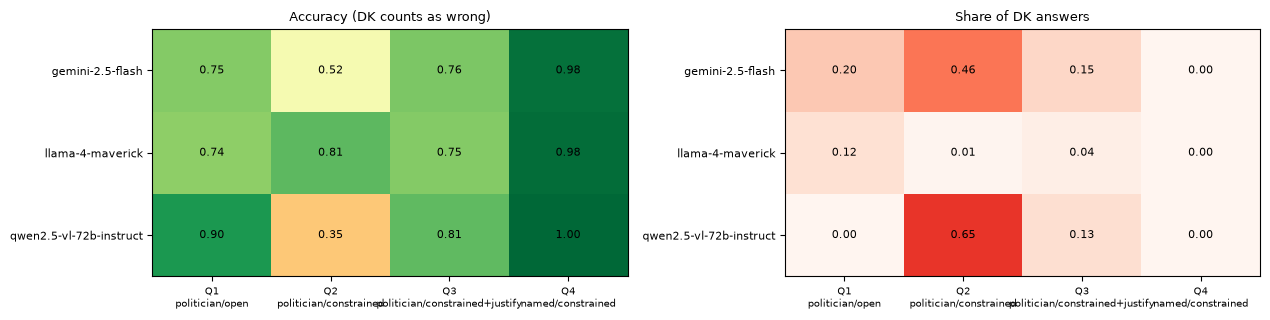

qid,Q1,Q2,Q3,Q4
majority_baseline,0.551,0.551,0.551,0.887


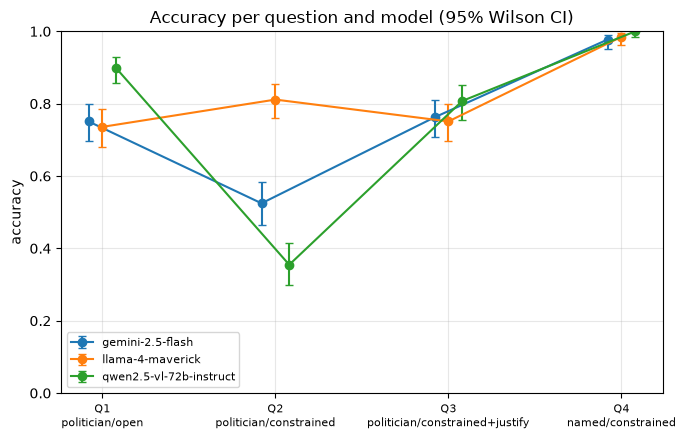

> **Result:** Accuracy range per model: gemini-2.5-flash 0.52–0.98 (best Q4), llama-4-maverick 0.74–0.98 (best Q4) and qwen2.5-vl-72b-instruct 0.35–1.00 (best Q4). The best combination is qwen2.5-vl-72b-instruct with Q4 (1.00). High DK shares lower the accuracy for qwen2.5-vl-72b-instruct Q2 (65%), gemini-2.5-flash Q2 (46%), gemini-2.5-flash Q1 (20%), gemini-2.5-flash Q3 (15%) and qwen2.5-vl-72b-instruct Q3 (13%). For Q4 the expected answers are imbalanced (baseline 0.89), so a high accuracy there is easy to reach; read it per group. The models agree most on Q4 (spread 0.02) and differ most on Q2 (spread 0.46 between the best and the worst model).

In [16]:
acc = U.show_accuracy(run)

## 5.4 Accuracy per image group
The same accuracy for each image group and model: a low value shows which kind of image makes a question fail.

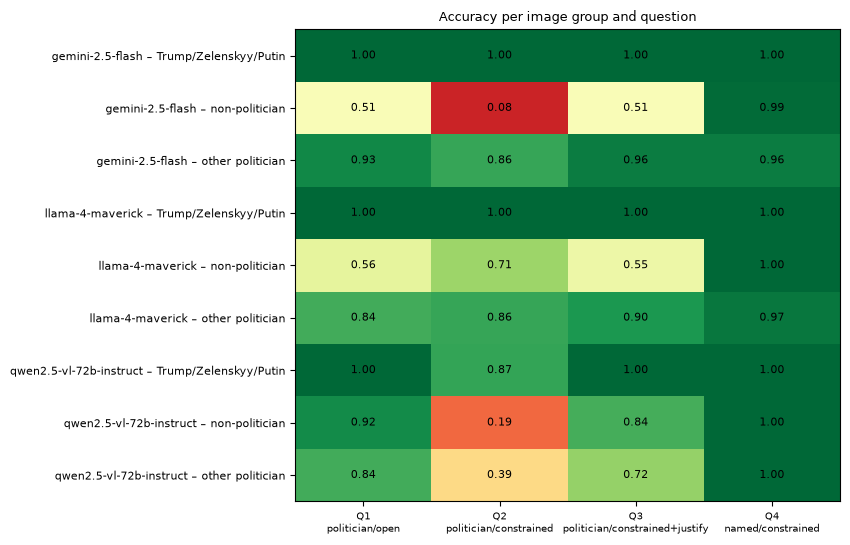

> **Result:** Weakest group and question per model – gemini-2.5-flash: non-politician with Q2 (0.08), llama-4-maverick: non-politician with Q3 (0.55) and qwen2.5-vl-72b-instruct: non-politician with Q2 (0.19).

In [17]:
U.show_groups(run, acc)

## 5.5 Which differences between questions are significant?
Each pair of questions is compared on the same images with an exact McNemar test (Holm-corrected). Blue = the row question is more accurate, red = less accurate, * = significant.

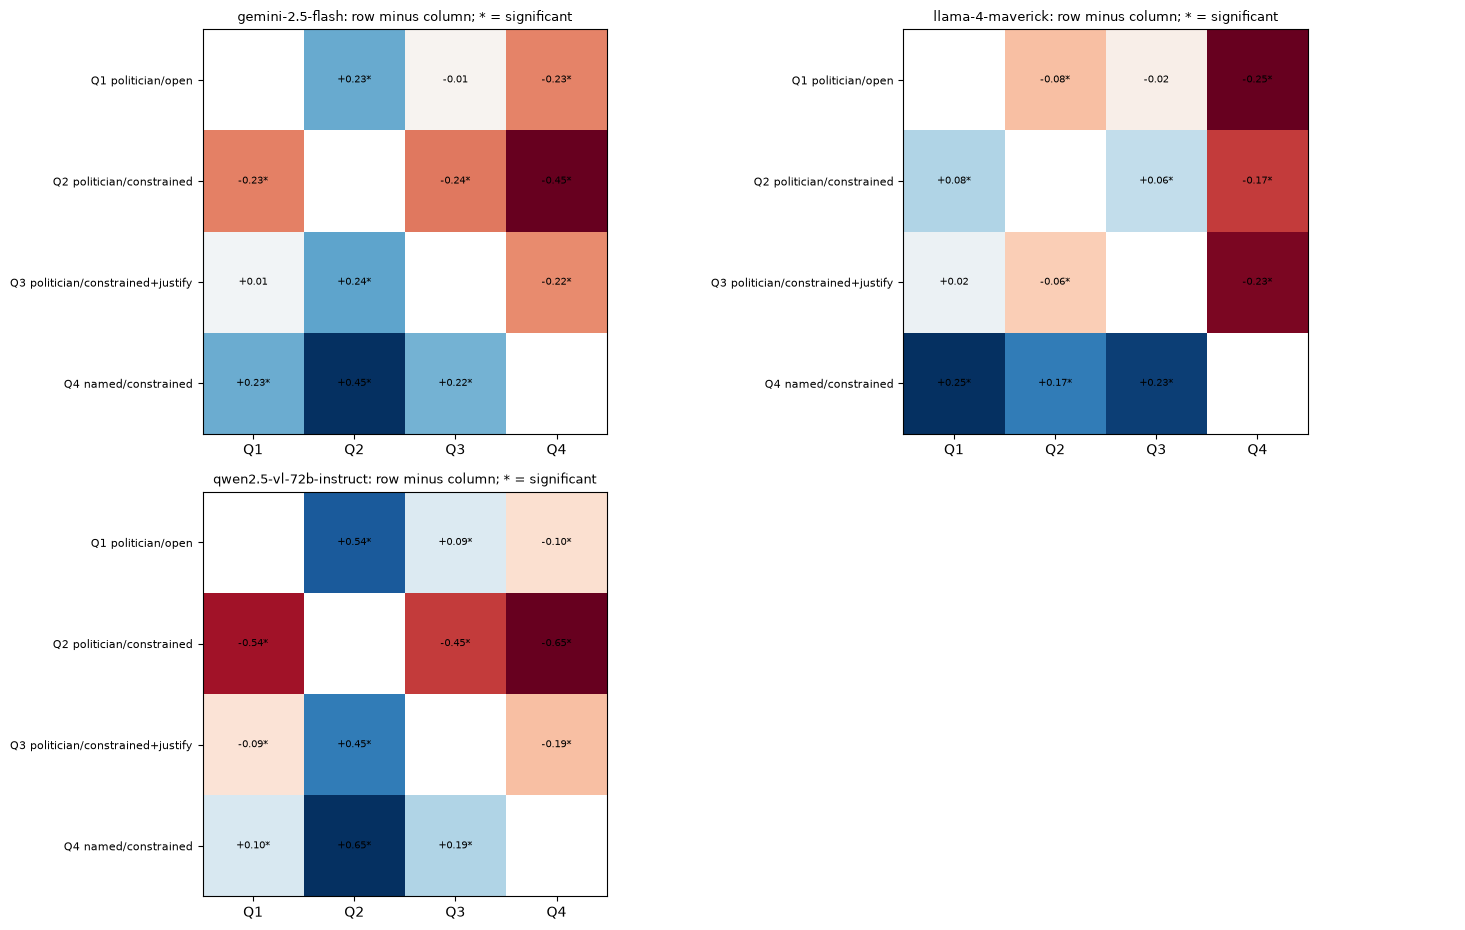

> **Result:** Significant question differences (of 6 pairs): gemini-2.5-flash 5, llama-4-maverick 5 and qwen2.5-vl-72b-instruct 6. 

In [18]:
tests = U.show_pairs(run)

## 5.6 Summary: which question to use?
The most accurate question per model and the questions that are not significantly worse. A question that is never significantly worse is a safe choice across models.

In [19]:
U.show_best(run, acc, tests)

,model,best_question,best_accuracy,not_significantly_worse,worst_question,worst_accuracy,mean_accuracy
0,gemini-2.5-flash,Q3,0.762,"Q1, Q3",Q2,0.525,0.679
1,llama-4-maverick,Q2,0.811,Q2,Q1,0.736,0.766
2,qwen2.5-vl-72b-instruct,Q1,0.898,Q1,Q2,0.355,0.687


> **Result:** Best question per model – gemini-2.5-flash: Q3 (0.76), llama-4-maverick: Q2 (0.81) and qwen2.5-vl-72b-instruct: Q1 (0.90). No question is the best or not significantly worse than the best for all models, so the choice of wording depends on the model.

## 5.7 Difficult images
How many answers go wrong per image, and the hardest images of each group. Errors on every question point to a hard image or a questionable label; errors on some questions point to the wording.

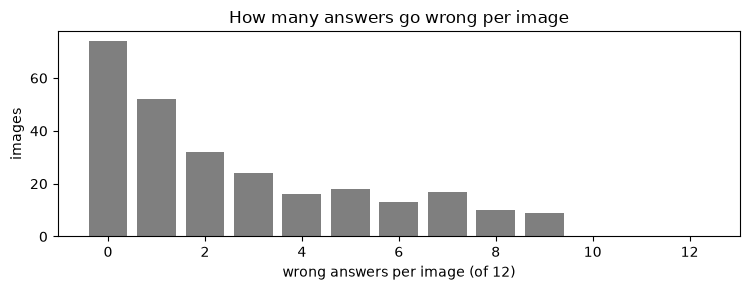

,,images,mean_share_wrong,hard_images (≥50% wrong)
group,subfolder,,,
non-politician,dataset_politicians,119,0.34,38
other politician,dataset_politicians,116,0.15,11
Trump/Zelenskyy/Putin,dataset_politicians,30,0.01,0


> **Result:** 74 of 265 images are answered correctly in all 12 answers, and 49 are wrong in half or more (38 non-politician, 11 other politician). The hardest group is non-politician (34% wrong answers on average), the easiest Trump/Zelenskyy/Putin (1%).

**Hardest images per group** – left: the image; right: expected answer (first row) and normalised answers, green = correct, red = wrong. Below: the raw wrong answers.

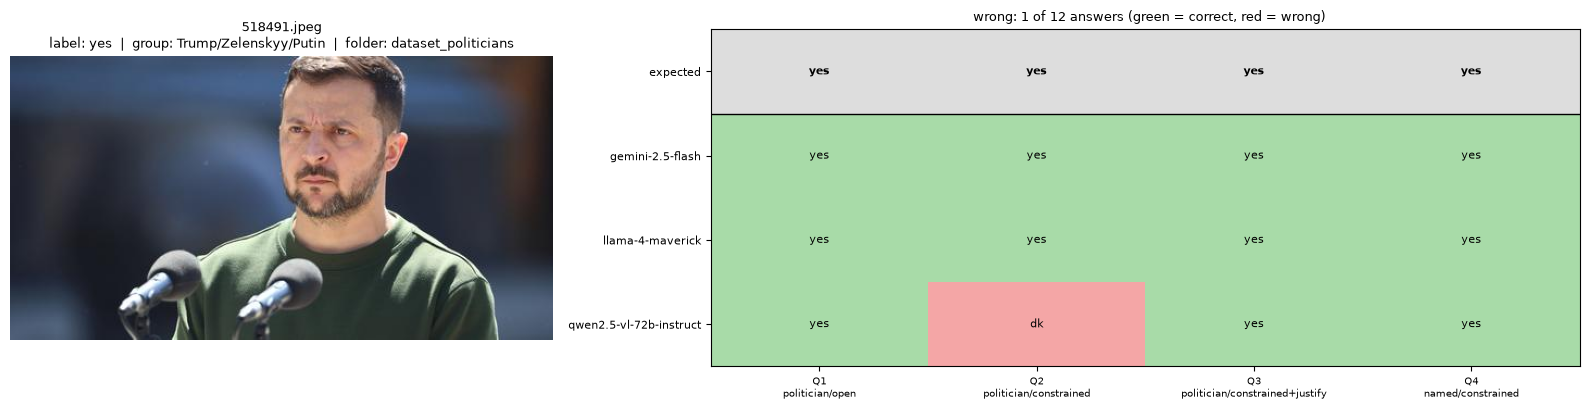

,model,qid,truth,pred,raw
0,qwen2.5-vl-72b-instruct,Q2,yes,dk,dk


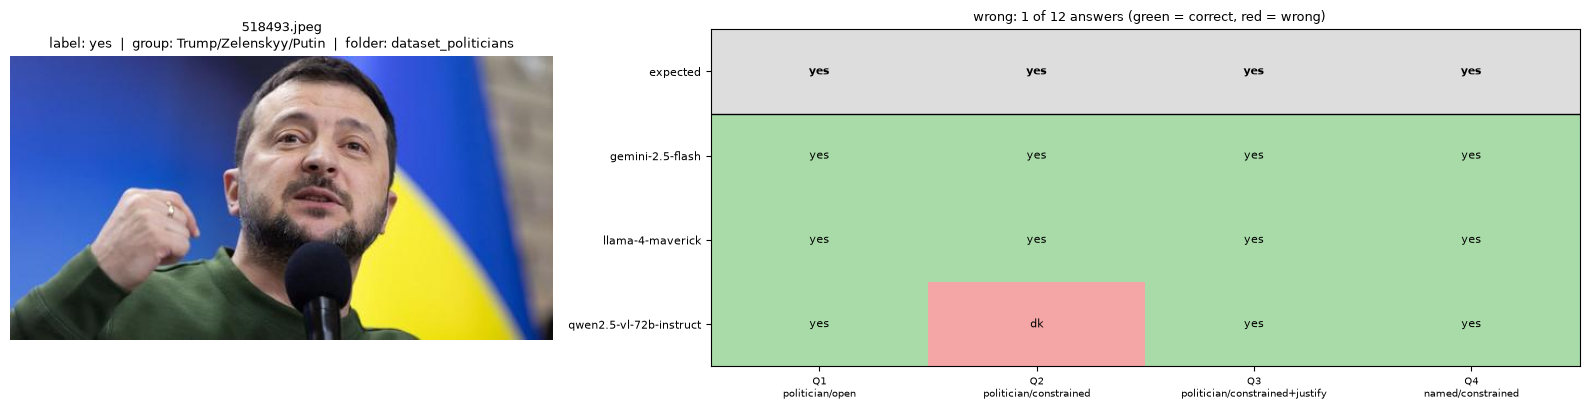

,model,qid,truth,pred,raw
0,qwen2.5-vl-72b-instruct,Q2,yes,dk,dk


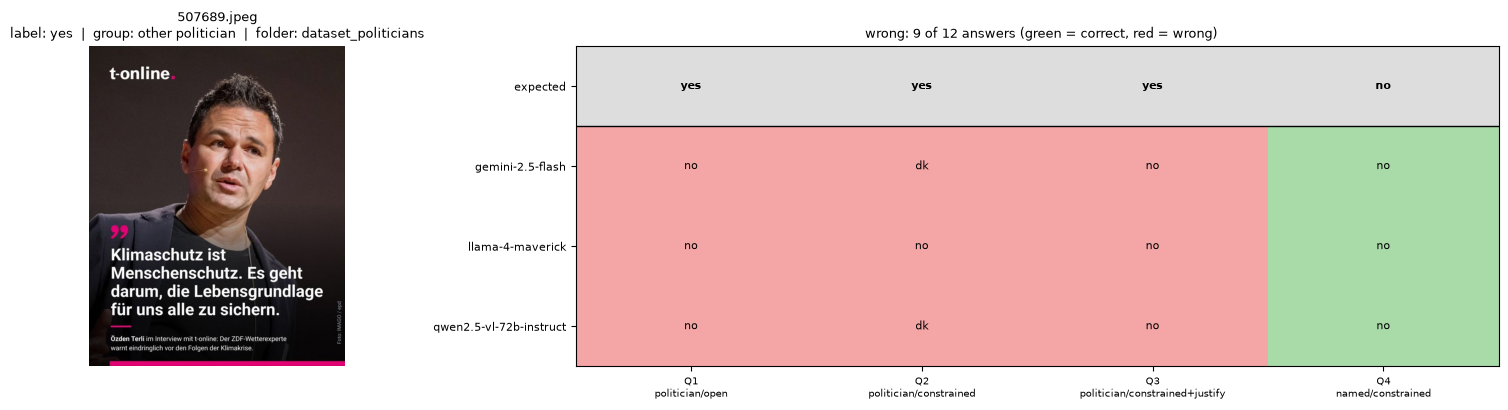

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,yes,no,"No, there is no politician in the picture. The person in the image is Özden Terli, a ZDF weather expert."
1,llama-4-maverick,Q1,yes,no,"The individual in the image is Özden Terli, a meteorologist who works for the ZDF, a German public broadcaster. While he is a public figure and discusses climat"
2,qwen2.5-vl-72b-instruct,Q1,yes,no,No
3,gemini-2.5-flash,Q2,yes,dk,dk
4,llama-4-maverick,Q2,yes,no,No.
5,qwen2.5-vl-72b-instruct,Q2,yes,dk,dk
6,gemini-2.5-flash,Q3,yes,no,"No. The person in the picture is Özden Terli, a ZDF weather expert, not a politician. The text explicitly states: ""Özden Terli im Interview mit t-online: Der Z"
7,llama-4-maverick,Q3,yes,no,"The individual in the image is Özden Terli, a meteorologist who works for the ZDF, a German public broadcaster. He is not a politician but rather a weather expe"
8,qwen2.5-vl-72b-instruct,Q3,yes,no,"No. The image shows Özden Terli, who is described as a ZDF weather expert, not a politician. The text mentions him being interviewed by t-online about climate"


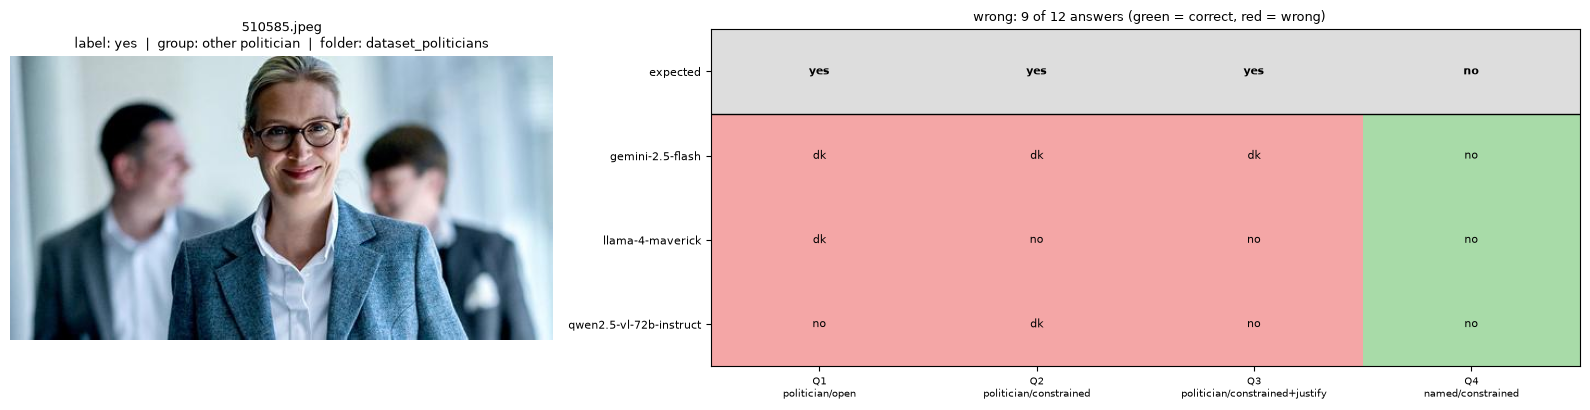

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,yes,dk,It is not possible to determine if there is a politician in the picture based solely on the visual information provided. The image shows a woman in professional
1,llama-4-maverick,Q1,yes,dk,The image does not provide enough information to determine if there is a politician in the picture.
2,qwen2.5-vl-72b-instruct,Q1,yes,no,No
3,gemini-2.5-flash,Q2,yes,dk,dk
4,llama-4-maverick,Q2,yes,no,No.
5,qwen2.5-vl-72b-instruct,Q2,yes,dk,dk
6,gemini-2.5-flash,Q3,yes,dk,"dk. There is no clear indication in the image itself that any of the individuals are politicians. Without additional context, it's impossible to determine thei"
7,llama-4-maverick,Q3,yes,no,"No. The image shows a woman in a professional setting, likely a business environment, with two men behind her. There is no clear indication that any of them are"
8,qwen2.5-vl-72b-instruct,Q3,yes,no,"No. The image shows a woman in business attire standing in what appears to be an office or professional setting. There are two men in the background, also dres"


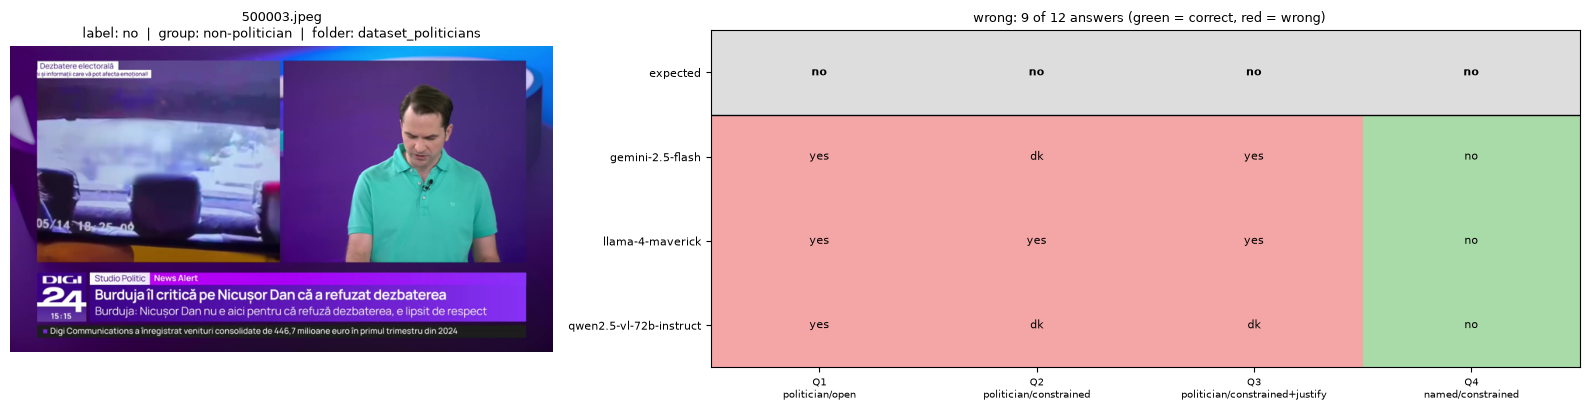

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,no,yes,"Yes, there is a politician in the picture."
1,llama-4-maverick,Q1,no,yes,Yes.
2,qwen2.5-vl-72b-instruct,Q1,no,yes,Yes.
3,gemini-2.5-flash,Q2,no,dk,dk
4,llama-4-maverick,Q2,no,yes,Yes.
5,qwen2.5-vl-72b-instruct,Q2,no,dk,dk
6,gemini-2.5-flash,Q3,no,yes,"Yes. The text on the screen mentions ""Nicușor Dan"" in the context of a debate, which strongly suggests he is a politician. The headline reads: ""Burduja îl crit"
7,llama-4-maverick,Q3,no,yes,The image shows a news broadcast with a man in a green shirt on the right side and a video clip on the left side. The text at the bottom of the screen is in Rom
8,qwen2.5-vl-72b-instruct,Q3,no,dk,"DK. The image shows a news broadcast with a man who appears to be a news anchor or reporter, not a politician. The text mentions Nicuşor Dan, but he is not visi"


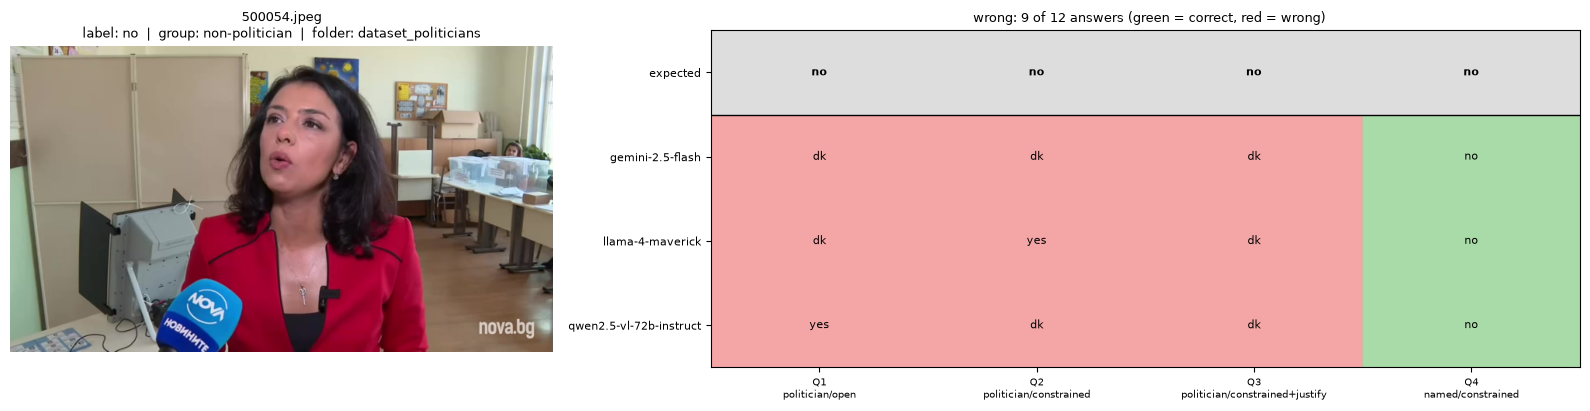

,model,qid,truth,pred,raw
0,gemini-2.5-flash,Q1,no,dk,It is not possible to determine if the person in the image is a politician from the provided visual information.
1,llama-4-maverick,Q1,no,dk,The image does not provide enough information to determine if the woman is a politician.
2,qwen2.5-vl-72b-instruct,Q1,no,yes,Yes
3,gemini-2.5-flash,Q2,no,dk,dk
4,llama-4-maverick,Q2,no,yes,Yes.
5,qwen2.5-vl-72b-instruct,Q2,no,dk,dk
6,gemini-2.5-flash,Q3,no,dk,"dk. There is a woman speaking into a microphone from ""NOVA news"" (a Bulgarian media outlet), which suggests she might be a public figure or involved in an even"
7,llama-4-maverick,Q3,no,dk,"The image shows a woman in a red blazer being interviewed by a news channel, as indicated by the microphone with the ""NOVA"" logo. The setting appears to be an o"
8,qwen2.5-vl-72b-instruct,Q3,no,dk,"DK. The image shows a woman speaking into a microphone with a ""NOVA"" logo, suggesting she might be a journalist or an interviewee. There are no clear indicators"


> **Result:** `518491.jpeg` (Trump/Zelenskyy/Putin): 1 of 12 answers wrong by qwen2.5-vl-72b-instruct; most often "dk" instead of "yes" (1x).<br>`518493.jpeg` (Trump/Zelenskyy/Putin): 1 of 12 answers wrong by qwen2.5-vl-72b-instruct; most often "dk" instead of "yes" (1x).<br>`507689.jpeg` (other politician): 9 of 12 answers wrong by gemini-2.5-flash, llama-4-maverick and qwen2.5-vl-72b-instruct; most often "no" instead of "yes" (7x).<br>`510585.jpeg` (other politician): 9 of 12 answers wrong by gemini-2.5-flash, llama-4-maverick and qwen2.5-vl-72b-instruct; most often "dk" instead of "yes" (5x).<br>`500003.jpeg` (non-politician): 9 of 12 answers wrong by gemini-2.5-flash, llama-4-maverick and qwen2.5-vl-72b-instruct; most often "yes" instead of "no" (6x).<br>`500054.jpeg` (non-politician): 9 of 12 answers wrong by gemini-2.5-flash, llama-4-maverick and qwen2.5-vl-72b-instruct; most often "dk" instead of "no" (7x).<br>Look at the images: errors on every question point to a hard image or a questionable label, errors on some questions to the wording.

In [20]:
U.show_difficult_images(run)